In [1]:
import h5py
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import cm, colors as mcolors



import scienceplots
plt.style.use(['science', 'no-latex'])


from pybaselines import Baseline, utils 
from scipy.signal import find_peaks
from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models

# Read the file

In [2]:
filename = ('/home/chavango/Master/DATA/SKAMPI_data/EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5')


# Let's porint the structure of the hdf5 file
def print_hdf5_structure(name, obj):
    indent = '  ' * name.count('/')
    if isinstance(obj, h5py.Group):
        print(f"{indent}Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        print(f"{indent}Dataset: {name}, Shape: {obj.shape}, Dtype: {obj.dtype}")

with h5py.File(filename, "r") as f:

    f.visititems(print_hdf5_structure)

    f.close()  # close the file

Dataset: history, Shape: (9,), Dtype: [('processingtime', 'S23'), ('software', 'S256'), ('version', 'S128'), ('comment', 'S256')]
Group: monitor
  Group: monitor/acu
    Dataset: monitor/acu/actual_timestamp, Shape: (2650,), Dtype: float64
    Group: monitor/acu/ambient_temp_correction_config
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_1, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_10, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_2, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_3, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_4, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_5a, Shape: (2650,), Dtype: float64
      Dataset:

# Transform to xarray dataset

In [ ]:
# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]


datasets = []

with h5py.File(filename, 'r') as f:
    for g in groups:
        
        # Load datasets correctly
        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]       # shape (n_time, n_freq)
        frequency = f[f"{g}/frequency"][1600:-60]/ 1e9
        time      = f[f"{g}/timestamp"][30:,0]     # often 2D
        ra 


        # Construct xarray dataset
        ds = xr.Dataset(
            {
                "spectrum": (("time", "frequency"), spectrum)
            },
            coords={
                "time": time,
                "frequency": frequency
            },
            attrs={
                "description": f"Spectrum data of {g}",
                "units": {
                    "spectrum": "dB",
                    "frequency": "GHz",
                    "time": "UTC"
                }
            }
        )

        ds = ds.expand_dims({"group": [g]})  # add group dimension

        datasets.append(ds)
    f.close() # close the file

datasets

[<xarray.Dataset> Size: 163MB
 Dimensions:    (group: 1, time: 634, frequency: 63877)
 Coordinates:
   * group      (group) object 8B 'scan/000/P1_ND0'
   * time       (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
   * frequency  (frequency) float64 511kB 1.793 1.793 1.793 ... 3.498 3.498 3.498
 Data variables:
     spectrum   (group, time, frequency) float32 162MB 1.883e+11 ... 4.159e+09
 Attributes:
     description:  Spectrum data of scan/000/P1_ND0
     units:        {'spectrum': 'dB', 'frequency': 'GHz', 'time': 'UTC'},
 <xarray.Dataset> Size: 163MB
 Dimensions:    (group: 1, time: 634, frequency: 63877)
 Coordinates:
   * group      (group) object 8B 'scan/000/P1_ND1'
   * time       (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09 1.679e+09
   * frequency  (frequency) float64 511kB 1.793 1.793 1.793 ... 3.498 3.498 3.498
 Data variables:
     spectrum   (group, time, frequency) float32 162MB 6.967e+10 ... 1.648e+09
 Attributes:
     description:  Spectrum da

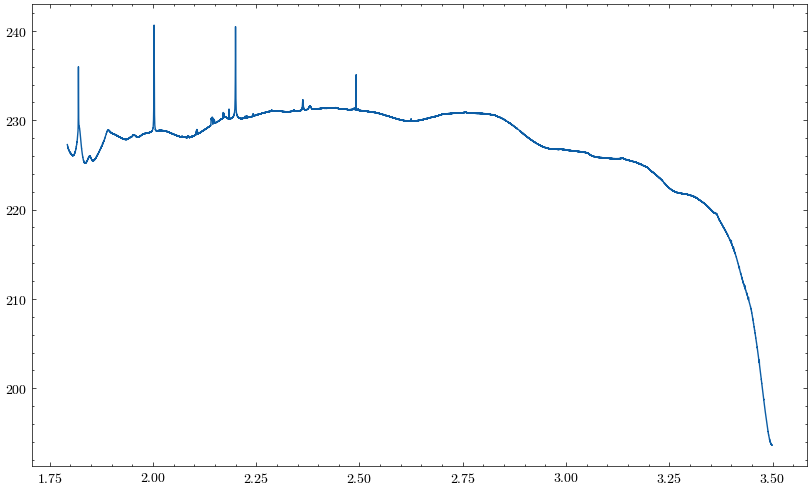

In [4]:
# Defeni the variablues
for i,g in enumerate(datasets):
    spectrum = (10*np.log10(datasets[i]['spectrum']**2)).values[0, :,:]
    time = datasets[i]['time'].values
    frequency = datasets[i]['frequency'].values

    # Date
    time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)
    date =  pd.to_datetime(time_utc[0].strftime('%Y-%m-%d'))

    # averege the spectrum over time
    avg_spec = np.nanmean(spectrum, axis=0)


    plt.figure(figsize=(10,6))
    plt.plot(frequency, avg_spec)

    break

# Flag the peaks using the `find_peaks`

In [5]:
# # find peaks by prominence and minimum width
# prominence = 

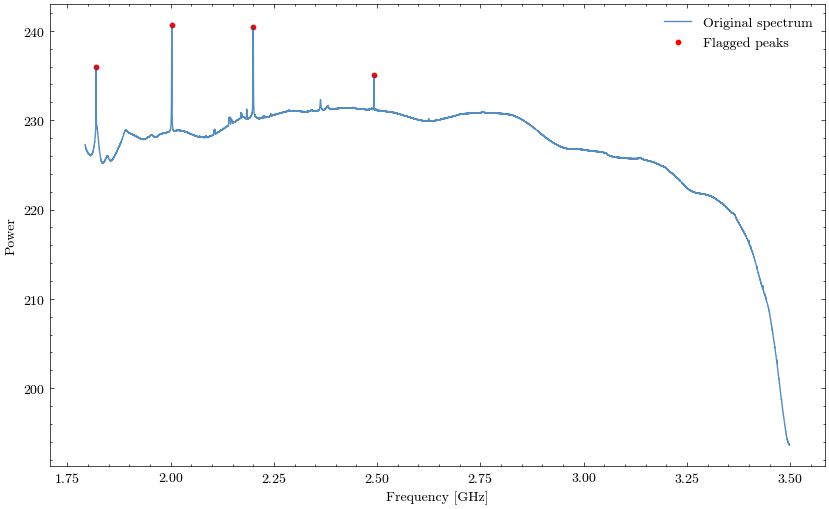

In [6]:
#find peaks by prominence and minimum width (tune these)
prominence = 2.0    # minimum vertical prominence (units same as spec)
width = 1           # minimum width in samples (set >1 to avoid single-sample spikes)

peaks, props = find_peaks(avg_spec, prominence=prominence, width=width)

# optional: filter by absolute height too
height_min = None   # e.g. 230 (set to None to ignore)
if height_min is not None:
    mask = avg_spec[peaks] > height_min
    peaks = peaks[mask]

# Plot results (original spectrum unchanged)
plt.figure(figsize=(10,6))
plt.plot(frequency, avg_spec, label='Original spectrum', alpha=0.7)
plt.scatter(frequency[peaks], avg_spec[peaks], color='red', s=10, label='Flagged peaks')
plt.xlabel('Frequency [GHz]')
plt.ylabel('Power')
plt.legend()
plt.show()

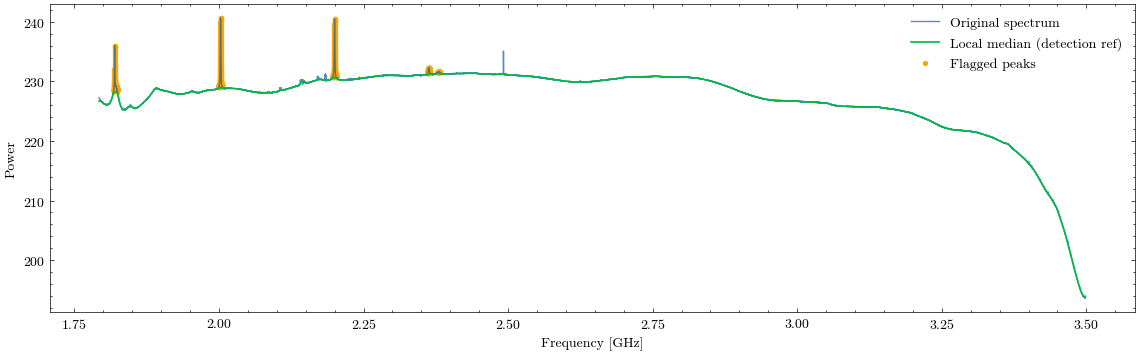

In [17]:

from scipy.ndimage import median_filter



# parameters
kernel_size = 501   # odd window length for local median (in channels). Tune: ~couple hundred to thousands
k = 6.0             # detection threshold in units of local MAD

# 1) local median (reference) -- used only for detection
local_med = median_filter(avg_spec, size=kernel_size, mode='reflect')

# 2) residual (detection-only)
resid = avg_spec - local_med

# 3) local MAD estimate (robust sigma proxy)
# compute absolute deviation from local median, followed by median filter
abs_dev = np.abs(avg_spec - local_med)
local_mad = median_filter(abs_dev, size=kernel_size, mode='reflect')
# convert MAD -> approx sigma: sigma ≈ 1.4826 * MAD  (for Gaussian)
local_sigma = 1.4826 * local_mad

# 4) flag where residual exceeds threshold
flags = resid > (k * local_sigma)

# Optionally morphological clean (remove tiny isolated flags)
from scipy.ndimage import binary_opening, binary_closing
flags = binary_opening(flags, structure=np.ones(100))
flags = binary_closing(flags, structure=np.ones(100))

# Plot (original unchanged)
plt.figure(figsize=(14,4))
plt.plot(frequency, avg_spec, label='Original spectrum', alpha=0.7)
plt.plot(frequency, local_med, color='C1', lw=1.2, label='Local median (detection ref)')
plt.scatter(frequency[flags], avg_spec[flags], color='orange', s=8, label='Flagged peaks')
plt.xlabel('Frequency [GHz]')
plt.ylabel('Power')
plt.legend()
plt.show()


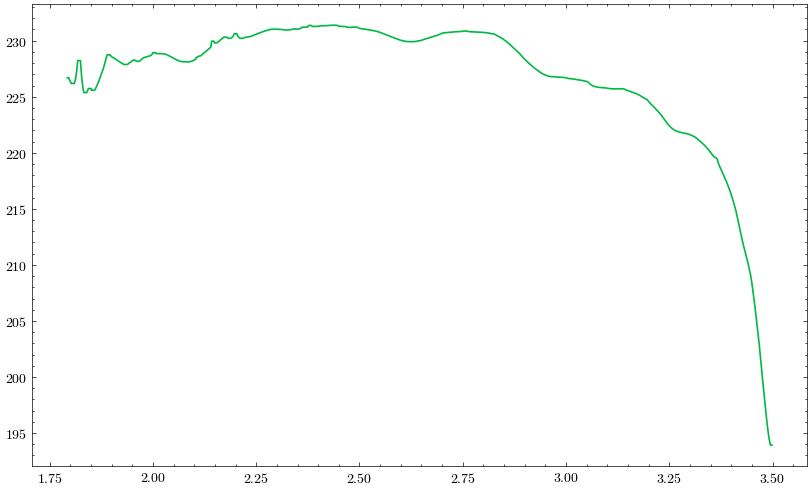

In [14]:
plt.figure(figsize=(10,6))
plt.plot(frequency, local_med, color='C1', lw=1.2, label='Local median (detection ref)')


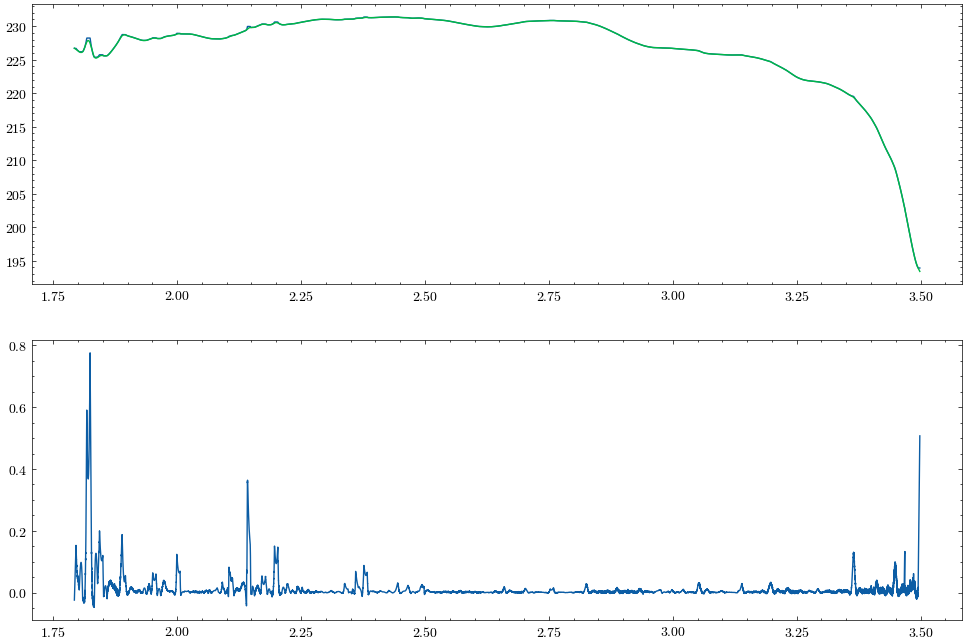

In [15]:
# apply the baseline correction on the data 
# Step 1: define the baseli fitting
baseline_fitter = Baseline(x_data=frequency)
bkg, params = baseline_fitter.asls(local_med, lam=1e7, p=0.03)

# Step 2: evaluate residual signal after baseline correction
baseline_correction = local_med - bkg


fig, ax =plt.subplots(2,1,figsize=(12,8))

ax[0].plot(frequency,local_med)
ax[0].plot(frequency,bkg)

ax[1].plot(frequency,baseline_correction)
